# Questão 4 — Plano tangente e reta normal

Visualizador independente para
$$f_1(x,y)=x^2+y^2,\qquad f_2(x,y)=\sqrt{x^2+y^2},$$
$$f_3(x,y)=\begin{cases}xy/\sqrt{x^2+y^2},&(x,y)\ne(0,0),\\0,&(x,y)=(0,0).\end{cases}$$

**Execução:** Python 3.10 ou superior, bibliotecas de `requirements.txt`, células em ordem. Em VS Code/Jupyter, selecione o ambiente em que instalou as bibliotecas. Os controles precisam de kernel ativo; o GitHub exibe apenas resultados salvos. Não é necessário executar outra questão primeiro.

Cada item apresenta **Análise na mão ✍️** e **Código 💻**. O gráfico é uma investigação; a diferenciabilidade é decidida pelas demonstrações. Fonte: PDF do trabalho de Cálculo II — UFAM, questão 4 e orientações gerais.


In [1]:
# 💻 Funções, classificação e geometria: nenhuma divisão por zero na origem
import numpy as np
import sympy as sp
import matplotlib.pyplot as plt
import plotly.graph_objects as go
import ipywidgets as widgets
from IPython.display import display, Markdown

NOMES = {'f1':'f₁: paraboloide', 'f2':'f₂: cone', 'f3':'f₃: xy/√(x²+y²)'}

def valor_funcao(nome, x, y):
    if nome not in NOMES:
        raise ValueError('Função desconhecida.')
    x,y=np.broadcast_arrays(np.asarray(x,dtype=float),np.asarray(y,dtype=float))
    r=np.hypot(x,y)
    if nome=='f1': return x*x+y*y
    if nome=='f2': return r
    # Forma equivalente que evita quadrados e produtos intermediários desnecessários.
    return np.divide(x,r,out=np.zeros_like(r),where=r>0)*y

def dados_ponto(nome,a,b):
    """Decisão matemática para as três funções conhecidas; origem testada exatamente."""
    if nome not in NOMES: raise ValueError('Função desconhecida.')
    a,b=float(a),float(b)
    if not np.isfinite([a,b]).all(): raise ValueError('Use coordenadas reais finitas.')
    if max(abs(a),abs(b))>5: raise ValueError('Neste visualizador, use a e b entre -5 e 5.')
    r=float(np.hypot(a,b)); origem=(a==0 and b==0)
    valido=nome=='f1' or not origem
    if nome=='f1': dx,dy=2*a,2*b
    elif origem: dx,dy=(None,None) if nome=='f2' else (0.0,0.0)
    elif nome=='f2': dx,dy=a/r,b/r
    else: dx,dy=(b/r)**3,(a/r)**3
    z=float(valor_funcao(nome,a,b))
    razao=('Polinômio: diferenciável em todo o plano.' if nome=='f1' else
           'Fórmula suave em uma vizinhança que não contém a origem.' if valido else
           'Na origem do cone, as parciais bilaterais não existem: |h|/h tem limites laterais distintos.' if nome=='f2' else
           'Na origem, as parciais são zero, mas o erro normalizado na diagonal é 1/2: não há diferencial.')
    d=dict(nome=nome,a=a,b=b,z=z,valido=valido,dx=dx,dy=dy,razao=razao)
    if valido:
        tx=np.array([1.,0.,dx]); ty=np.array([0.,1.,dy]); normal=np.cross(tx,ty)
        d.update(Tx=tx,Ty=ty,N=normal,P=np.array([a,b,z]))
    return d

def altura_plano(d,x,y):
    if not d['valido']: raise ValueError('Não há plano tangente via diferencial neste ponto.')
    return d['z']+d['dx']*(np.asarray(x)-d['a'])+d['dy']*(np.asarray(y)-d['b'])

def erro_local(d,h,k):
    """Erro e erro normalizado. Em pontos inválidos, referência z=0 apenas diagnóstica."""
    h,k=np.broadcast_arrays(np.asarray(h,dtype=float),np.asarray(k,dtype=float))
    r=np.hypot(h,k)
    base=d['z']+(d['dx']*h+d['dy']*k if d['valido'] else 0)
    e=np.abs(valor_funcao(d['nome'],d['a']+h,d['b']+k)-base)
    q=np.divide(e,r,out=np.full_like(r,np.nan),where=r>0)
    return e,q

print('Funções carregadas. A classificação vem das demonstrações, não da malha gráfica.')


Funções carregadas. A classificação vem das demonstrações, não da malha gráfica.


## Item 1 — Selecionar um ponto da superfície

### Análise na mão ✍️
As três funções estão definidas em todo $\mathbb R^2$, considerando a definição por partes de $f_3$. Escolhido $(a,b)$, o ponto do gráfico é $P=(a,b,f(a,b))$.

No visualizador dos itens 2–4, escolha a função e as coordenadas, ou um exemplo pronto. O intervalo disponível é $[-5,5]$ para cada coordenada. O controle de zoom mostra uma vizinhança de raio horizontal $\ell=10^{-p}$ em cada direção. Mudar o zoom mantém o ponto escolhido.


In [2]:
# 💻 Exemplos de pontos: nenhum caso depende de um notebook anterior
for nome in NOMES:
    for a,b in [(0,0),(1,0),(1,1)]:
        d=dados_ponto(nome,a,b)
        print(f'{nome}: (a,b)=({a},{b}) → P=({a},{b},{d["z"]:.6g})')


f1: (a,b)=(0,0) → P=(0,0,0)
f1: (a,b)=(1,0) → P=(1,0,1)
f1: (a,b)=(1,1) → P=(1,1,2)
f2: (a,b)=(0,0) → P=(0,0,0)
f2: (a,b)=(1,0) → P=(1,0,1)
f2: (a,b)=(1,1) → P=(1,1,1.41421)
f3: (a,b)=(0,0) → P=(0,0,0)
f3: (a,b)=(1,0) → P=(1,0,0)
f3: (a,b)=(1,1) → P=(1,1,0.707107)


## Item 2 — Plano tangente e reta normal

### Análise na mão ✍️
Se a função for diferenciável em $(a,b)$, o plano e a reta normal são
$$z=f(a,b)+f_x(a,b)(x-a)+f_y(a,b)(y-b),$$
$$(x,y,z)=P+t(-f_x(a,b),-f_y(a,b),1),\qquad t\in\mathbb R.$$

As derivadas a usar são:

| Função | $f_x(a,b)$ | $f_y(a,b)$ | Onde a fórmula vale |
|:---|:---:|:---:|:---|
| $f_1$ | $2a$ | $2b$ | Todo o plano |
| $f_2$ | $a/r$ | $b/r$ | $r=\sqrt{a^2+b^2}>0$ |
| $f_3$ | $b^3/r^3$ | $a^3/r^3$ | $r>0$ |

Por exemplo, para $f_3$, $\partial_x(xy/r)=y/r-x^2y/r^3=y^3/r^3$. Fora da origem, os denominadores não se anulam e as parciais são contínuas em uma vizinhança do ponto: isso garante diferenciabilidade.

Na origem, as fórmulas de $f_2$ e $f_3$ acima não se aplicam. A decisão específica será demonstrada no item 4. O programa não anunciará plano tangente ou reta normal via diferencial nesses casos.


In [3]:
# 💻 Conferência simbólica das derivadas fora da origem (x,y reais)
x,y=sp.symbols('x y',real=True)
expressoes={'f1':x*x+y*y,'f2':sp.sqrt(x*x+y*y),'f3':x*y/sp.sqrt(x*x+y*y)}
for nome,expr in expressoes.items():
    print(nome,': f_x =',sp.simplify(sp.diff(expr,x)), '| f_y =',sp.simplify(sp.diff(expr,y)))


f1 : f_x = 2*x | f_y = 2*y
f2 : f_x = x/sqrt(x**2 + y**2) | f_y = y/sqrt(x**2 + y**2)
f3 : f_x = y**3/(x**2 + y**2)**(3/2) | f_y = x**3/(x**2 + y**2)**(3/2)


## Item 3 — Vetores da parametrização e produto vetorial

### Análise na mão ✍️
A parametrização é $R(x,y)=(x,y,f(x,y))$. Nos pontos diferenciáveis:
$$T_x=R_x(a,b)=(1,0,f_x),\qquad T_y=R_y(a,b)=(0,1,f_y).$$
$$N=T_x\times T_y=(-f_x,-f_y,1).$$
Temos $N\cdot T_x=N\cdot T_y=0$. O vetor normal é sempre não nulo, pois sua terceira componente é 1. Portanto os vetores tangentes são linearmente independentes e determinam o plano.

As setas no visualizador têm **comprimentos ajustados para caber no zoom**, preservando as direções. Os valores originais dos vetores aparecem no texto. O trecho de reta desenhado também é finito, embora a reta normal matemática tenha $t\in\mathbb R$.


In [4]:
# 💻 Figura reutilizável: superfície, ponto, plano, reta e setas

def adicionar_seta(fig,p,v,comprimento,nome,cor):
    direcao=np.asarray(v,dtype=float)/np.linalg.norm(v)
    fim=p+comprimento*direcao
    fig.add_trace(go.Scatter3d(x=[p[0],fim[0]],y=[p[1],fim[1]],z=[p[2],fim[2]],
                              mode='lines',name=nome,line=dict(color=cor,width=7)))
    fig.add_trace(go.Cone(x=[fim[0]],y=[fim[1]],z=[fim[2]],u=[direcao[0]],v=[direcao[1]],
                         w=[direcao[2]],anchor='tip',sizemode='absolute',sizeref=comprimento*.18,
                         colorscale=[[0,cor],[1,cor]],showscale=False,showlegend=False,
                         hoverinfo='skip'))

def construir_figura(d,p=0,plano=True,reta=True,vetores=True):
    lado=10.0**(-p)
    v=np.linspace(-lado,lado,61)
    h,k=np.meshgrid(v,v)
    xx,yy=d['a']+h,d['b']+k
    zz=valor_funcao(d['nome'],xx,yy)
    fig=go.Figure(go.Surface(x=xx,y=yy,z=zz,name='superfície',showscale=False,
                             colorscale='Viridis',opacity=.78))
    P=np.array([d['a'],d['b'],d['z']])
    if d['valido']:
        if plano:
            fig.add_trace(go.Surface(x=xx,y=yy,z=altura_plano(d,xx,yy),name='plano tangente',
                                     showlegend=True,showscale=False,opacity=.4,
                                     colorscale=[[0,'#f4a261'],[1,'#f4a261']]))
        if reta:
            ts=np.linspace(-1.4*lado/np.linalg.norm(d['N']),1.4*lado/np.linalg.norm(d['N']),2)
            linha=P[:,None]+d['N'][:,None]*ts
            fig.add_trace(go.Scatter3d(x=linha[0],y=linha[1],z=linha[2],mode='lines',
                                      name='reta normal',line=dict(color='#9d4edd',width=5,dash='dash')))
        if vetores:
            for chave,cor in [('Tx','#e63946'),('Ty','#2374d8'),('N','#7b2cbf')]:
                adicionar_seta(fig,P,d[chave],.75*lado,chave,cor)
    elif d['nome']=='f3':
        # São tangentes dos CORTES, não uma base de plano tangente à superfície.
        for chave,vv,cor in [('tangente do corte y=0',[1,0,0],'#e63946'),
                             ('tangente do corte x=0',[0,1,0],'#2374d8')]:
            if vetores: adicionar_seta(fig,P,vv,.75*lado,chave,cor)
    fig.add_trace(go.Scatter3d(x=[P[0]],y=[P[1]],z=[P[2]],mode='markers',
                              name='P na superfície',marker=dict(color='black',size=6)))
    estado='diferenciável' if d['valido'] else 'sem plano tangente via diferencial'
    fig.update_layout(title=f'{NOMES[d["nome"]]} em ({d["a"]:g},{d["b"]:g}): {estado}',
                      scene=dict(xaxis_title='x',yaxis_title='y',zaxis_title='z',aspectmode='data'),
                      height=600,margin=dict(l=0,r=0,t=65,b=0),legend=dict(orientation='h'))
    return fig

def texto_ponto(d):
    txt=(f'**P = ({d["a"]:g}, {d["b"]:g}, {d["z"]:.8g}).**  \n'
         f'**Justificativa:** {d["razao"]}')
    if d['valido']:
        txt+=(f'\n\n**Plano:** z = {d["z"]:.8g} + ({d["dx"]:.8g})(x − ({d["a"]:g})) '
              f'+ ({d["dy"]:.8g})(y − ({d["b"]:g})).'
              f'\n\n**Reta:** (x,y,z) = ({d["a"]:g},{d["b"]:g},{d["z"]:.8g}) '
              f'+ t({-d["dx"]:.8g},{-d["dy"]:.8g},1).'
              f'\n\n**Vetores originais:** T_x = {d["Tx"].tolist()}; '
              f'T_y = {d["Ty"].tolist()}; N = {d["N"].tolist()}.')
    else:
        txt+='\n\n**Plano e reta normal via diferencial não são construídos.**'
        if d['nome']=='f3':
            txt+=' Os vetores exibidos pertencem aos cortes coordenados; seu produto vetorial vertical não valida um plano tangente à superfície.'
    return txt


## Item 4 — Origem versus pontos regulares

### Análise na mão ✍️

| Função | Na origem | Fora da origem |
|:---|:---|:---|
| $f_1$ | Diferenciável; plano $z=0$, normal vertical | Diferenciável |
| $f_2$ | Não diferenciável; parciais bilaterais inexistentes | Diferenciável |
| $f_3$ | Contínua, com parciais zero, mas não diferenciável | Diferenciável |

**Paraboloide:** $f_1(h,k)=h^2+k^2=\rho^2$. Como $L=0$, $|R|/\rho=\rho\to0$; o plano $z=0$ é válido.

**Cone:** $f_2(h,0)=|h|$. O quociente incremental $|h|/h$ vale 1 à direita e −1 à esquerda. A parcial em $x$ não existe; em $y$ acontece o mesmo. Logo não há diferencial. O quociente $|f_2(h,k)|/\rho=1$ também refuta a aproximação por $z=0$, mas essa referência não é um plano candidato obtido por parciais.

**Terceira função:** nos eixos, $f_3(h,0)=f_3(0,k)=0$, portanto as duas parciais na origem são zero. A única aplicação linear candidata é $L=0$. Entretanto, em $(h,k)=(t,t)$, o erro normalizado vale $1/2$, não zero. Além disso, $|f_3(h,k)|\le\rho/2$ prova continuidade, que por si só não garante diferenciabilidade.

**Por que cortes com tangentes não bastam?** Para $f_3$ na origem, as tangentes dos cortes são $(1,0,0)$ e $(0,1,0)$ e o produto vetorial é $(0,0,1)$. Mesmo assim, o plano horizontal falha na diagonal. As duas direções dos cortes não controlam a aproximação em toda a vizinhança.


### Visualizador interativo dos itens 1–4 💻
Selecione uma função, digite $(a,b)$ e clique em **Atualizar**. Um exemplo pronto aplica a alteração imediatamente. Escolha o zoom e o que deseja exibir. Nos casos inválidos, plano e reta ficam indisponíveis; as mensagens explicam a hipótese que falhou. Valores muito próximos da origem são classificados como pontos regulares se forem de fato não nulos, sem tolerância artificial que os transforme na origem.


In [5]:
# 💻 Controles e painéis que substituem o conteúdo anterior
funcao=widgets.Dropdown(options=[(v,k) for k,v in NOMES.items()],value='f1',description='Função:')
a_input=widgets.BoundedFloatText(value=0,min=-5,max=5,description='a:')
b_input=widgets.BoundedFloatText(value=0,min=-5,max=5,description='b:')
zoom=widgets.IntSlider(value=0,min=0,max=4,description='p (zoom):',continuous_update=False)
mostrar_plano=widgets.Checkbox(value=True,description='Plano')
mostrar_reta=widgets.Checkbox(value=True,description='Reta normal')
mostrar_vetores=widgets.Checkbox(value=True,description='Vetores')
botao=widgets.Button(description='Atualizar',button_style='primary')
exemplos=widgets.Dropdown(description='Exemplos:',options=[('Escolha um exemplo',None),
    ('Paraboloide na origem',('f1',0,0)),('Cone na origem',('f2',0,0)),
    ('f₃ na origem',('f3',0,0)),('Paraboloide em (1,1)',('f1',1,1)),
    ('Cone em (1,0)',('f2',1,0)),('f₃ em (1,1)',('f3',1,1)),
    ('f₃ perto da origem',('f3',.001,.001))],layout=widgets.Layout(width='420px'))
display(widgets.VBox([funcao,widgets.HBox([a_input,b_input,botao]),exemplos,zoom,
                      widgets.HBox([mostrar_plano,mostrar_reta,mostrar_vetores])]))
painel_txt=display(Markdown('Preparando…'),display_id=True)
painel_fig=display(go.Figure(),display_id=True)

def atualizar_modelo(change=None):
    try:
        d=dados_ponto(funcao.value,a_input.value,b_input.value)
        mostrar_plano.disabled=mostrar_reta.disabled=not d['valido']
        painel_txt.update(Markdown(texto_ponto(d)))
        painel_fig.update(construir_figura(d,zoom.value,mostrar_plano.value,
                                          mostrar_reta.value,mostrar_vetores.value))
    except ValueError as erro:
        painel_txt.update(Markdown(f'**Entrada inválida:** {erro}'))
        painel_fig.update(go.Figure())

def aplicar_exemplo(change):
    if change['new'] is not None:
        nome,a,b=change['new']
        funcao.value=nome; a_input.value=a; b_input.value=b
        atualizar_modelo()

botao.on_click(atualizar_modelo)
exemplos.observe(aplicar_exemplo,names='value')
for controle in (funcao,zoom,mostrar_plano,mostrar_reta,mostrar_vetores):
    controle.observe(atualizar_modelo,names='value')
atualizar_modelo()


**P = (0, 0, 0).**  
**Justificativa:** Polinômio: diferenciável em todo o plano.

**Plano:** z = 0 + (0)(x − (0)) + (0)(y − (0)).

**Reta:** (x,y,z) = (0,0,0) + t(-0,-0,1).

**Vetores originais:** T_x = [1.0, 0.0, 0.0]; T_y = [0.0, 1.0, 0.0]; N = [0.0, 0.0, 1.0].

## Item 5 — Aproximação local e comportamento do erro

### Análise na mão ✍️
No ponto diferenciável $p=(a,b)$, escrevemos
$$R(h,k)=f(a+h,b+k)-f(a,b)-f_x(a,b)h-f_y(a,b)k.$$
A definição exige $|R(h,k)|/\sqrt{h^2+k^2}\to0$. Apenas $|R|\to0$ não é suficiente.

Para o paraboloide, em **qualquer** ponto, a expansão dá exatamente $R(h,k)=h^2+k^2=\rho^2$. Assim, o erro normalizado é $\rho$.

Para $f_2$ e $f_3$ em um ponto regular, há uma vizinhança afastada da origem onde são $C^2$. Pelo resto de Taylor e uma cota para a Hessiana nessa vizinhança, $|R|\le C\rho^2$ e $|R|/\rho\le C\rho\to0$. A constante e a vizinhança dependem do ponto; perto da origem, a região apropriada precisa ser menor.

Na origem do cone, o erro contra a referência $z=0$ é $\rho$, com quociente 1. Na origem de $f_3$, o erro absoluto também tende a zero, mas na diagonal o quociente é $1/2$. **A superfície se aproximar em altura do plano não prova tangência via diferencial.**

Os gráficos abaixo usam três direções: eixo $x$, diagonal e direção transversal. Para pontos regulares de $f_2$ e $f_3$, os passos são menores que metade da distância do ponto à origem. Quocientes menores que a precisão de ponto flutuante podem oscilar; a justificativa continua sendo analítica.


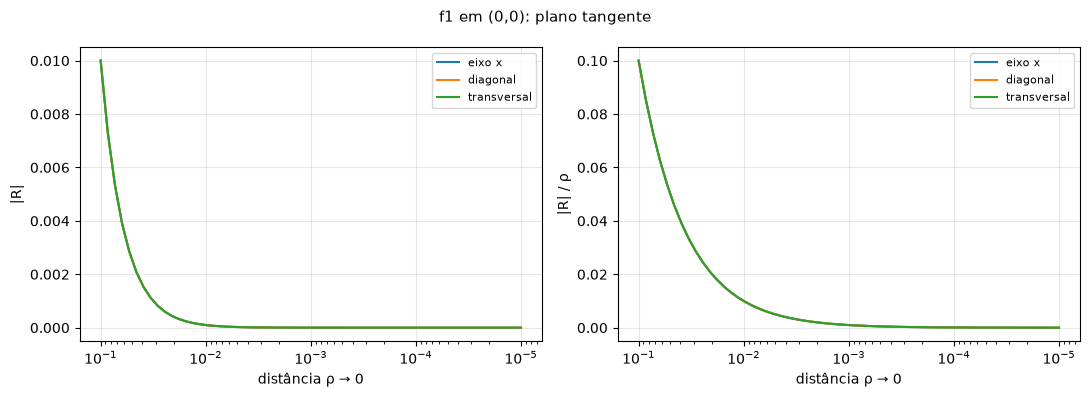

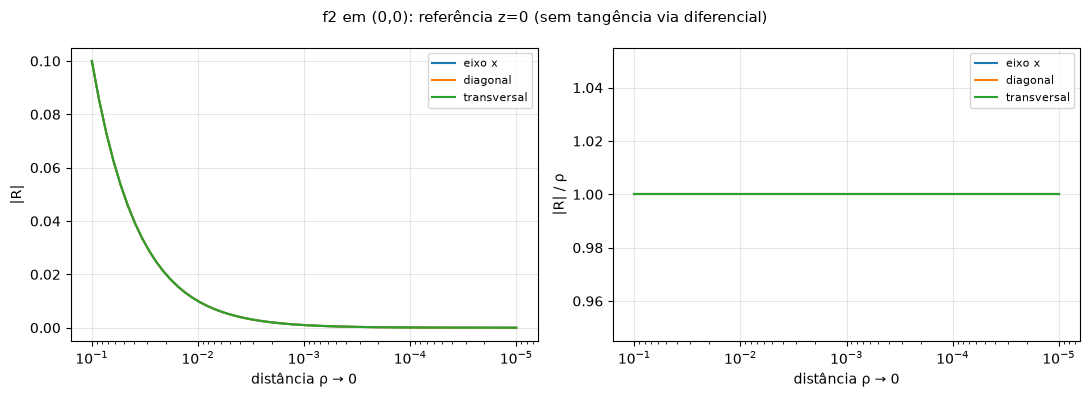

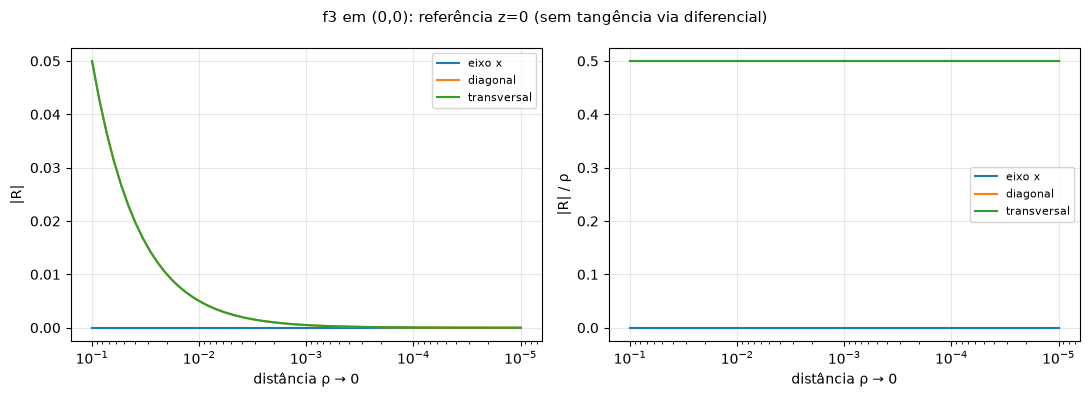

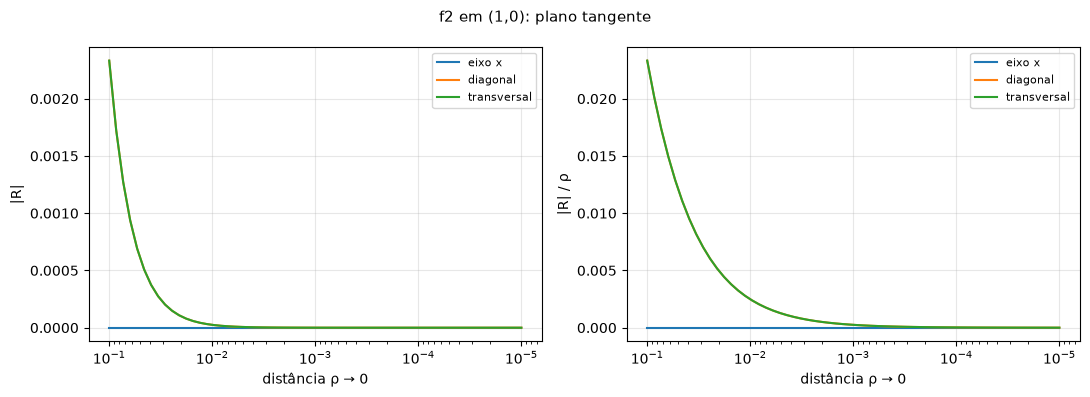

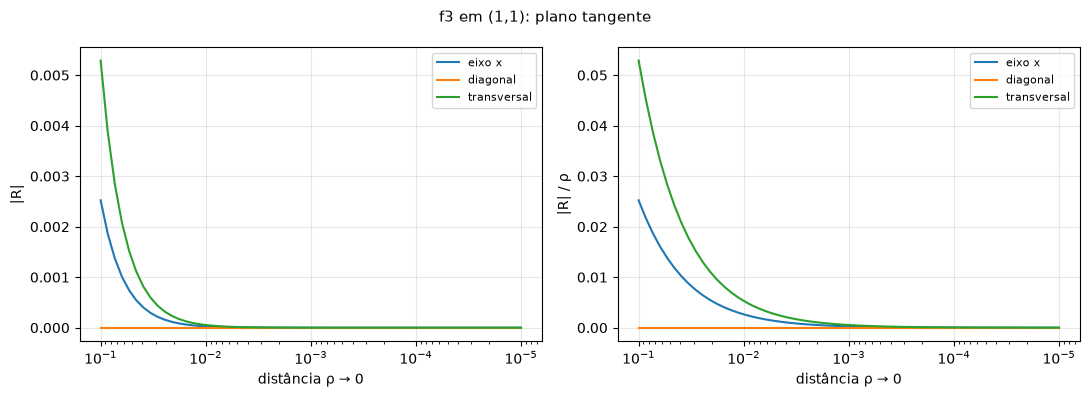

In [6]:
# 💻 Gráficos de erro; esta função também produz as imagens de apoio ao relatório
DIRECOES={'eixo x':np.array([1.,0.]),'diagonal':np.array([1.,1.])/np.sqrt(2),
          'transversal':np.array([1.,-1.])/np.sqrt(2)}

def construir_erros(d):
    distancia=np.hypot(d['a'],d['b'])
    inicio=min(.1,distancia/4) if d['valido'] and d['nome']!='f1' else .1
    rhos=np.geomspace(inicio,inicio*1e-4,60)
    fig,axs=plt.subplots(1,2,figsize=(11,4))
    for rotulo,u in DIRECOES.items():
        e,q=erro_local(d,rhos*u[0],rhos*u[1])
        axs[0].plot(rhos,e,label=rotulo)
        axs[1].plot(rhos,q,label=rotulo)
    for ax in axs:
        ax.set_xscale('log'); ax.invert_xaxis()
        ax.set_xlabel('distância ρ → 0'); ax.grid(alpha=.3); ax.legend(fontsize=8)
    axs[0].set_ylabel('|R|'); axs[1].set_ylabel('|R| / ρ')
    referencia='plano tangente' if d['valido'] else 'referência z=0 (sem tangência via diferencial)'
    fig.suptitle(f'{d["nome"]} em ({d["a"]:g},{d["b"]:g}): {referencia}',fontsize=11)
    fig.tight_layout()
    return fig

# Resultados estáticos preservados ao abrir o notebook; cada caso tem sua própria figura.
for nome,a,b in [('f1',0,0),('f2',0,0),('f3',0,0),('f2',1,0),('f3',1,1)]:
    fig_erro=construir_erros(dados_ponto(nome,a,b))
    plt.show(); plt.close(fig_erro)


Na origem, as parciais são zero, mas o erro normalizado na diagonal é 1/2: não há diferencial.

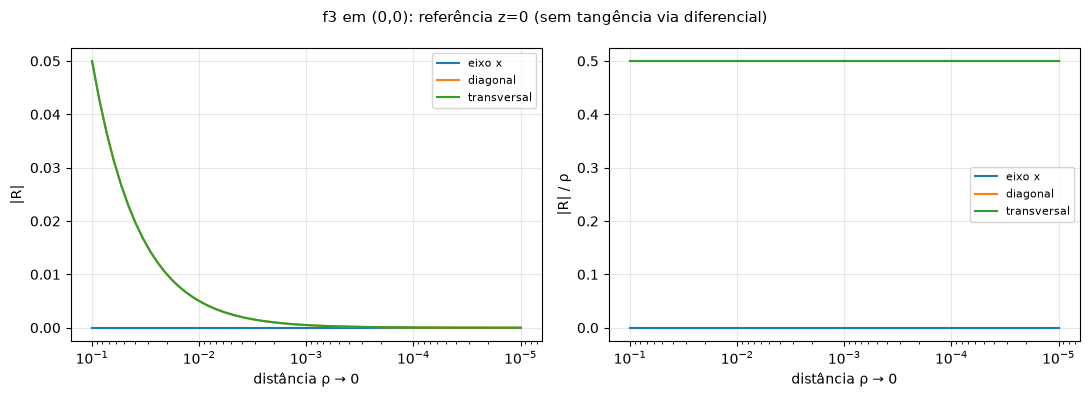

In [7]:
# 💻 Controle independente para investigar os erros em outros pontos
funcao_erro=widgets.Dropdown(options=[(v,k) for k,v in NOMES.items()],value='f3',description='Função:')
a_erro=widgets.BoundedFloatText(value=0,min=-5,max=5,description='a:')
b_erro=widgets.BoundedFloatText(value=0,min=-5,max=5,description='b:')
botao_erro=widgets.Button(description='Comparar erros',button_style='info')
display(widgets.HBox([funcao_erro,a_erro,b_erro,botao_erro]))
painel_erro_txt=display(Markdown(''),display_id=True)
painel_erro=display(Markdown(''),display_id=True)

def atualizar_erros(_=None):
    try:
        d=dados_ponto(funcao_erro.value,a_erro.value,b_erro.value)
        fig=construir_erros(d)
        painel_erro_txt.update(Markdown(d['razao']))
        painel_erro.update(fig); plt.close(fig)
    except ValueError as erro:
        painel_erro_txt.update(Markdown(f'**Entrada inválida:** {erro}'))
        painel_erro.update(Markdown(''))

botao_erro.on_click(atualizar_erros)
atualizar_erros()


## Conferências matemáticas reproduzíveis

Os testes abaixo confrontam fórmulas simbólicas, posições, ortogonalidade e taxas de erro. Eles conferem a implementação; não substituem as demonstrações. Em particular, não se usa o fato de um gráfico parecer plano para decidir diferenciabilidade.


In [8]:
# 💻 Derivadas, vetor normal, incidência e comportamento do erro
for nome in NOMES:
    for a,b in [(0,0),(1,0),(1,1),(-1,2),(1e-8,-1e-8)]:
        d=dados_ponto(nome,a,b)
        assert d['valido']==(nome=='f1' or a!=0 or b!=0)
        if d['valido']:
            np.testing.assert_allclose(np.cross(d['Tx'],d['Ty']),d['N'])
            np.testing.assert_allclose(np.dot(d['N'],d['Tx']),0,atol=1e-13)
            np.testing.assert_allclose(np.dot(d['N'],d['Ty']),0,atol=1e-13)
            np.testing.assert_allclose(altura_plano(d,a,b),d['z'])
            np.testing.assert_allclose(d['N'],[-d['dx'],-d['dy'],1])
        else:
            assert 'N' not in d and 'Tx' not in d and 'Ty' not in d
# Conferência simbólica independente para evitar repetir a mesma fórmula numérica.
for nome in NOMES:
    for a,b in [(1,0),(1,1),(-1,2)]:
        d=dados_ponto(nome,a,b)
        esperado=[float(sp.diff(expressoes[nome],v).subs({x:a,y:b})) for v in (x,y)]
        np.testing.assert_allclose([d['dx'],d['dy']],esperado,rtol=1e-12,atol=1e-12)
rhos=np.geomspace(.1,1e-5,30)
u=DIRECOES['diagonal']
for a,b in [(0,0),(1,1),(-1,2)]:
    e,q=erro_local(dados_ponto('f1',a,b),rhos*u[0],rhos*u[1])
    np.testing.assert_allclose(e,rhos*rhos,rtol=2e-5,atol=1e-14)
np.testing.assert_allclose(erro_local(dados_ponto('f2',0,0),rhos*u[0],rhos*u[1])[1],1)
np.testing.assert_allclose(erro_local(dados_ponto('f3',0,0),rhos*u[0],rhos*u[1])[1],.5)
for nome in ('f2','f3'):
    d=dados_ponto(nome,1,1)
    # Testa uma direção em que o erro não é identicamente zero.
    _,q=erro_local(d,rhos,0*rhos)
    assert q[-1]<q[0]/100
print('Conferências: derivadas simbólicas, classificação, incidência, ortogonalidade e erros: OK.')


Conferências: derivadas simbólicas, classificação, incidência, ortogonalidade e erros: OK.


## Roteiro de demonstração oral

1. Comece com o paraboloide na origem: o plano horizontal e a reta vertical são válidos.
2. Mude para o cone na origem: explique a inexistência das parciais bilaterais; plano e normal via diferencial desaparecem.
3. Escolha $f_3$ na origem: as tangentes dos eixos existem, mas o erro diagonal impede um plano via diferencial.
4. Selecione cone em $(1,0)$ e $f_3$ em $(1,1)$: exiba $T_x,T_y,N$, confira o produto vetorial e use o zoom.
5. Compare erro absoluto e erro normalizado. Explique por que o primeiro pode diminuir mesmo em um caso inválido.

**Resposta à pergunta orientadora:** a diferenciabilidade fornece uma aproximação linear cujo resto é $o(\rho)$ em todas as direções; o gráfico dessa aproximação afim é o plano tangente. Cortes coordenados com tangentes, isoladamente, não garantem esse controle.

**Organização:** este arquivo é individual e independente. A junção das questões permanece reservada para autorização posterior. Os resumos e imagens de apoio ficam em `apoio_relatorio/`.
